In [1]:
import sklearn
import seaborn as sns
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

In [34]:
import pandas as pd
import matplotlib.pyplot as plt
from pprint import pprint
import math
pd.__version__

'1.4.2'

In [3]:
def read_data(file):
    df = pd.read_parquet(file)
    print(f"Number of columns for {file}: {len(df.columns)}")
    print(df.dtypes)
    #convert to datetime64[ns] to int64
    converted_start_end_df = df.astype({"tpep_pickup_datetime": "int", "tpep_dropoff_datetime": "int"})
    df['duration'] = (converted_start_end_df['tpep_dropoff_datetime'] - converted_start_end_df['tpep_pickup_datetime']) * 1.6666666666667E-11
    print(df.duration.describe())
    print(f"min: {df.duration.min()}")
    print(f"max: {df.duration.max()}")
    df_b060 = df[(df.duration >= 1) & (df.duration <= 60)]
    # Q:What fraction of the records left after you dropped the outliers?
    fraction = len(df_b060) / len(df)
    print(f"fraction: {fraction*100:.2f}")
    return df_b060

In [4]:
train_df = read_data("./data/yellow_tripdata_2023-01.parquet")

Number of columns for ./data/yellow_tripdata_2023-01.parquet: 19
VendorID                          int64
tpep_pickup_datetime     datetime64[ns]
tpep_dropoff_datetime    datetime64[ns]
passenger_count                 float64
trip_distance                   float64
RatecodeID                      float64
store_and_fwd_flag               object
PULocationID                      int64
DOLocationID                      int64
payment_type                      int64
fare_amount                     float64
extra                           float64
mta_tax                         float64
tip_amount                      float64
tolls_amount                    float64
improvement_surcharge           float64
total_amount                    float64
congestion_surcharge            float64
airport_fee                     float64
dtype: object
count    3.066766e+06
mean     1.566900e+01
std      4.259435e+01
min     -2.920000e+01
25%      7.116667e+00
50%      1.151667e+01
75%      1.830000e+01
max    

In [5]:
val_df = read_data("./data/yellow_tripdata_2023-02.parquet")

Number of columns for ./data/yellow_tripdata_2023-02.parquet: 19
VendorID                          int32
tpep_pickup_datetime     datetime64[ns]
tpep_dropoff_datetime    datetime64[ns]
passenger_count                 float64
trip_distance                   float64
RatecodeID                      float64
store_and_fwd_flag               object
PULocationID                      int32
DOLocationID                      int32
payment_type                      int64
fare_amount                     float64
extra                           float64
mta_tax                         float64
tip_amount                      float64
tolls_amount                    float64
improvement_surcharge           float64
total_amount                    float64
congestion_surcharge            float64
Airport_fee                     float64
dtype: object
count    2.913955e+06
mean     1.601591e+01
std      4.284210e+01
min     -4.361667e+01
25%      7.250000e+00
50%      1.180000e+01
75%      1.876667e+01
max    

/home/codespace/anaconda3/lib/python3.9/site-packages/seaborn/distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
/home/codespace/anaconda3/lib/python3.9/site-packages/seaborn/distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


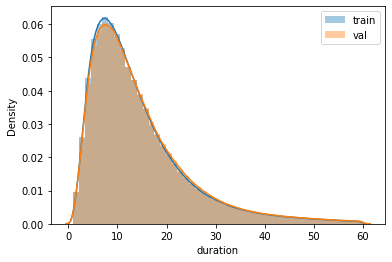

In [6]:
sns.distplot(train_df.duration, label="train")
sns.distplot(val_df.duration, label="val")
plt.legend()

In [7]:
# one-hot encoding
def encode(dataframe):
    dataframe['PU_DO'] = dataframe['PULocationID'].astype(str) + "_" + dataframe['DOLocationID'].astype(str)

In [8]:
encode(train_df)
encode(val_df)

In [27]:
categorical = ["PULocationID", "DOLocationID"]
numerical = ['trip_distance']

vectorizer = DictVectorizer()

train_dicts = train_df[categorical].astype(str).to_dict(orient='records')
pprint(train_dicts[:5])
X_train = vectorizer.fit_transform(train_dicts)
del train_dicts

[{'DOLocationID': '141', 'PULocationID': '161'},
 {'DOLocationID': '237', 'PULocationID': '43'},
 {'DOLocationID': '238', 'PULocationID': '48'},
 {'DOLocationID': '7', 'PULocationID': '138'},
 {'DOLocationID': '79', 'PULocationID': '107'}]


In [28]:
val_dicts = val_df[categorical].astype(str).to_dict(orient='records')
pprint(val_dicts[:5])
X_val = vectorizer.transform(val_dicts)
del val_dicts

[{'DOLocationID': '163', 'PULocationID': '142'},
 {'DOLocationID': '26', 'PULocationID': '132'},
 {'DOLocationID': '145', 'PULocationID': '161'},
 {'DOLocationID': '236', 'PULocationID': '148'},
 {'DOLocationID': '244', 'PULocationID': '137'}]


In [29]:
print(X_val.shape)

(2855879, 515)


In [30]:
target = "duration"
y_train = train_df[target].values
y_val = val_df[target].values

In [31]:
lr = LinearRegression()
lr.fit(X_train,y_train)

LinearRegression()

In [37]:
y_pred = lr.predict(X_train)

rmse = math.sqrt(mean_squared_error(y_train, y_pred))
print(rmse)

7.6485415389196


In [38]:
y_pred_val = lr.predict(X_val)

rmse_val = math.sqrt(mean_squared_error(y_val, y_pred_val))
print(rmse_val)

7.810133573087361
